In [1]:
import pickle
import matplotlib.pyplot as plt
import numpy as np

EXP = 'exp/q3'

def load_eval(run_dir, max_step=1000000):
    data = pickle.load(open(f'{EXP}/{run_dir}/log.pkl', 'rb'))
    rows = [r for r in data['eval'] if r['step'] <= max_step]
    steps = [r['step'] for r in rows]
    sr = [r['eval/success_rate'] for r in rows]
    return np.array(steps), np.array(sr)

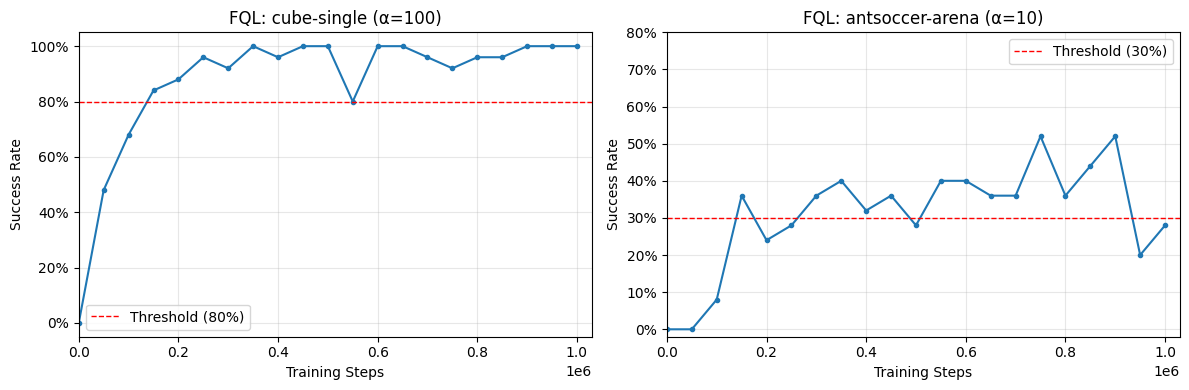

In [2]:
# Plot 1: Best FQL agents on cube-single and antsoccer
best_cube = 'sd0_20260403_200500_fql_cube-single-play-singletask-task1-v0_a1.0_a100.0'
best_ants = 'sd0_20260403_200500_fql_antsoccer-arena-navigate-singletask-task1-v0_a1.0_a10.0'

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, run, title, threshold, ylim in [
    (axes[0], best_cube, 'cube-single (α=100)', 0.80, (-0.05, 1.05)),
    (axes[1], best_ants, 'antsoccer-arena (α=10)', 0.30, (-0.02, 0.8)),
]:
    steps, sr = load_eval(run)
    ax.plot(steps, sr, marker='o', markersize=3, linewidth=1.5)
    ax.axhline(threshold, color='red', linestyle='--', linewidth=1, label=f'Threshold ({threshold:.0%})')
    ax.set_xlabel('Training Steps')
    ax.set_ylabel('Success Rate')
    ax.set_title(f'FQL: {title}')
    ax.set_xlim(0, 1030000)
    ax.set_ylim(ylim)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fql_best_agents.png', dpi=150, bbox_inches='tight')
plt.show()